# Energy profile plot

In [1]:
import os, sys
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from IPython.display import display

sys.path.append(os.path.abspath(os.path.join('..', 'src')))

from kinetic_model.energy_profile.energy_processing import calculate_relative_energies, calculate_energies_with_references
from kinetic_model.energy_profile.energy_profile import EnergyProfile
import yaml
from collections import OrderedDict

In [2]:
temperatures = list(np.linspace(300, 600, 11))         # Can be varied
pressures = list(101325. * np.linspace(1, 50, 11))           # Can be carried
models = ['QM-QM_TPSSh-PBED3']   # Options: ['QM-QM_M06L-PBED3', 'QM-QM_TPPSh-PBED3]  
pathways = ['trigonal',]         # Options: ['trigonal', 'hexagonal']
ref_struc = '1'                 # Choose either 1 or 5
energy_type = 'Gibbs free energy'   # Options: ['Electronic energy', 'Enthalpy', 'Gibbs free energy']
energy_unit = 'kJ/mol'              # Options: ['eV', 'kJ/mol', 'kcal/mol']

custom_order = ["1", "2", "3", "4", "5", "5a", "6", "1p", "7", "8", "9", "5p", "6p", "1pp", "10", "11", "12", "5pp", "6pp", "1ppp", "2-3", "3-4", "6-1p", "7-8", "8-9", "6p-1pp", "10-11", "11-12", "6pp-1ppp"]  # Use for sorting the intermediates in a table (or pd.DataFrame)

rel_results = calculate_relative_energies(
    structures_dir=os.path.abspath('../data/structures'),
    molecules_dir=os.path.abspath('../data/gas-phase-molecules'),
    temperatures=temperatures,
    models=models,
    ref_struc=ref_struc,
    pathways=pathways,
    pressures=pressures
)

columns_to_display = ['model', 'method', 'pathway', 'system', 'system_name', 'order', 'pressure', 'temperature', 'rel_E_eV', 'rel_H_eV', 'rel_G_eV']

# Filter only rows where 'order' is in the custom_order list
rel_results_filtered = rel_results[rel_results['order'].isin(custom_order)].copy()

# Assign the categorical order
rel_results_filtered['order'] = pd.Categorical(
    rel_results_filtered['order'], categories=custom_order, ordered=True
)

# Sort and select columns
rel_results_sorted = rel_results_filtered.sort_values(by='order')
formatted_df_tri = rel_results_sorted[columns_to_display]
formatted_df_tri.loc[:, ['rel_G_KjpMol']] = formatted_df_tri['rel_G_eV'] * 96.485

In [3]:
dft = formatted_df_tri.query('temperature == 300 & pressure >= 1e5 & pressure <= 1.1e5')\
    .reset_index(drop=True).copy()
print(dft.shape)
dft = dft.astype({'order': 'str'})
dE = dft.loc[dft.order == '2', 'rel_G_eV'].values[0]
dft['rel_G_eV'] -= dE
dft.loc[-1, :] = dft.loc[dft.order=='1p', :].iloc[0]
dft.loc[-1, 'order'] = '2p'
dft.loc[-1, 'rel_G_eV'] += dE

dft.loc[-2, :] = dft.loc[dft.order=='1pp', :].iloc[0]
dft.loc[-2, 'order'] = '2pp'
dft.loc[-2, 'rel_G_eV'] += dE

dft.loc[-3, :] = dft.loc[dft.order=='1ppp', :].iloc[0]
dft.loc[-3, 'order'] = '2ppp'
dft.loc[-3, 'rel_G_eV'] += dE

(29, 12)


## Plots 1

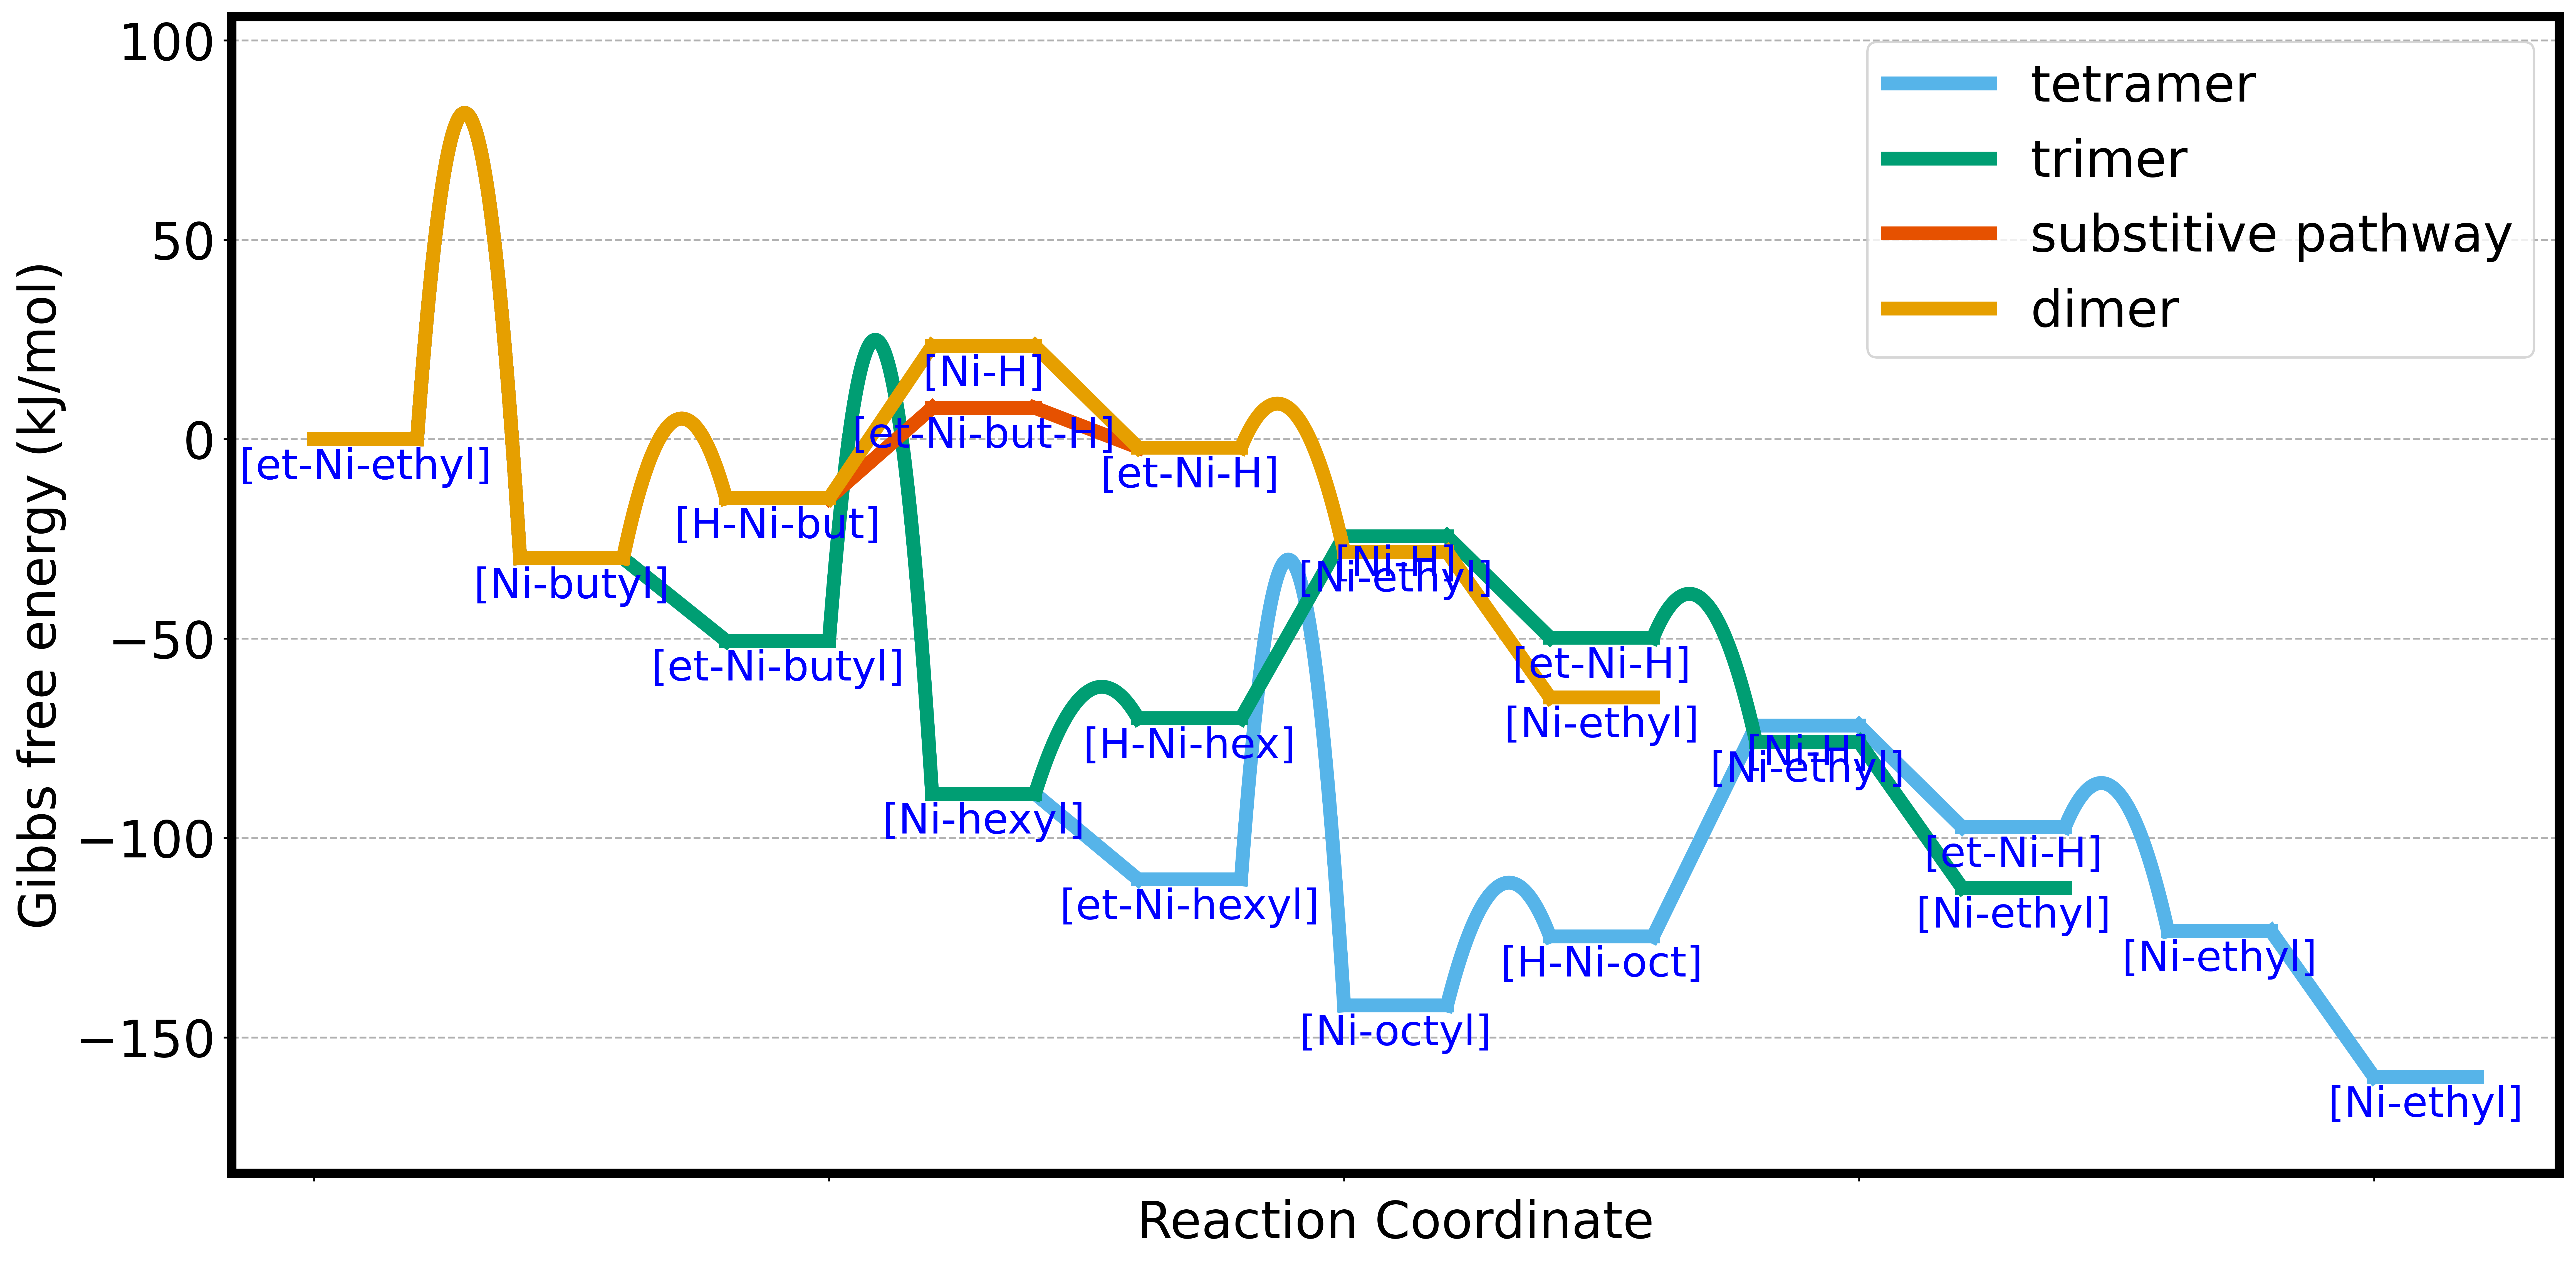

In [51]:
add_energies = False # Add the energy of the plotted intermediates and TS
add_names = True    # Add the name of the plotted intermediates
energy_type='Gibbs free energy'
energy_unit = 'kJ/mol'

# This gives general settings for the plot
with open(os.path.abspath('./settings.yaml'), "r") as f:
            settings = yaml.safe_load(f)

# This gives more information on the sequences of intermediates to be plotted, the respective labels and colors
with open(os.path.abspath('./c8_energy_profiles_settings.yaml'), "r") as f:
            plot_settings = yaml.safe_load(f)
plot_settings['sequences'].append('1-->2-->3-->4-->5a-->6')
plot_settings['labels'].append('substitive pathway')
plot_settings['colors'].append("#E65100")
for key, value in plot_settings.items():
     value[-1], value[-2] = value[-2], value[-1]  # Swap last two entries to have the new pathway at the end



EP = EnergyProfile(
    dft.query('pathway == "trigonal"'),
    energy_type=energy_type, 
    energy_unit=energy_unit)

plot_settings['sequences'] = ['2-->3-->7-->8-->10-->11-->12-->5pp-->6pp-->1ppp-->2ppp',
 '2-->3-->7-->8-->9-->5p-->6p-->1pp-->2pp',
 '2-->3-->4-->5a-->6',
 '2-->3-->4-->5-->6-->1p-->2p']

systems_ls = []
labels = []
for line in plot_settings['sequences']:
    systems = line.split(sep='-->')
    systems_ls.append(systems)
try:
    colors = plot_settings['colors']
except:
    colors = settings['color_palette'][1:]

position_map = OrderedDict()
for systems in systems_ls:
    for i, system in enumerate(systems):
        position = 2 * i
        if system not in position_map:
            position_map[system] = position
xmax = max(position_map.values()) + 1

EP.plot()
energy_values = []
for systems in systems_ls:
    tmp_values = EP.get_energy_range(systems)
    energy_values.extend(tmp_values)

ymin = min(energy_values)
ymax = max(energy_values)
yrange = ymax - ymin
padding = 0.10 * yrange

for i, systems in enumerate(systems_ls):
    for system in systems:
        position = position_map[system]

        if system == systems[0]:
            EP.add_level(system=system, 
                         position=position, 
                         label=plot_settings['labels'][i], 
                         color=colors[i])
        else:
            EP.add_level(system=system, 
                         position=position, 
                         color=colors[i])

        # EP.add_intermediate_energy_label(system=system, 
        #                                  position=position, 
        #                                  fontsize=18)

    for system1, system2 in zip(systems[:-1], systems[1:]):
        EP.add_connection(system1=system1, 
                          system2=system2, 
                          color=colors[i])
        # EP.add_ts_energy_label(system1=system1, 
        #                        system2=system2,
        #                        fontsize=18)
        
if add_energies:
    for i, systems in enumerate(systems_ls):
        for j, system in enumerate(systems):
            position = position_map[system]
            EP.add_intermediate_energy_label(system=system, 
                                               position=position, 
                                               fontsize=18)
        for system1, system2 in zip(systems[:-1], systems[1:]):
            EP.add_ts_energy_label(system1=system1, 
                                   system2=system2,
                                   fontsize=18)
if add_names:
    for i, systems in enumerate(systems_ls):
        for j, system in enumerate(systems):
            position = position_map[system]
            EP.add_structure_name(system=system,
                                  position=position, 
                                  fontsize=18)
 
EP.show(xmin=-0.8,
        xmax=21.8,
        ymin=ymin,
        ymax=ymax,
        padding=padding,
        legend=True)

In [5]:
data = dft.copy()
data['order'] = data['order'].astype(str)
ethylene_ads = data.loc[data.order == '1', 'rel_G_eV'].values - data.loc[data.order == '2', 'rel_G_eV'].values
data.loc[-1, :] = data.loc[data['order'] == '1p', :].iloc[0]
data.loc[-1, 'order'] = '2p'
data.loc[-1, 'rel_G_eV'] -= ethylene_ads
data.loc[-1, 'system_name'] = 'et-Ni-ethyl'

In [6]:
plot_settings

{'sequences': ['1-->2-->3-->7-->8-->10-->11-->12-->5pp-->6pp-->1ppp',
  '1-->2-->3-->7-->8-->9-->5p-->6p-->1pp',
  '1-->2-->3-->4-->5a-->6',
  '1-->2-->3-->4-->5-->6-->1p'],
 'labels': ['tetramer', 'trimer', 'substitive pathway', 'dimer'],
 'colors': ['#56B4E9', '#009E73', '#E65100', '#E69F00']}

In [9]:
EP = EnergyProfile(
    data, 
    energy_type=energy_type, 
    energy_unit=energy_unit)

plot_sequence_1 =  '1-->2-->3-->4-->5a-->6'   # Show the sequence of intermediate along which the profile is constructed
plot_sequence_2 = '1-->2-->3-->7-->8'
plot_sequence_3 = '1-->2-->3-->4-->5-->6-->1p-->2p'

systems_ls = [plot_sequence_1.split(sep='-->'), 
              plot_sequence_2.split(sep='-->'),
              plot_sequence_3.split(sep='-->'), 
              ]

position_map = OrderedDict()
for systems in systems_ls:
    for i, system in enumerate(systems):
        position = 2 * i
        if system not in position_map:
            position_map[system] = position
    
xmax = max(position_map.values()) + 1

EP.plot()
energy_values = []
for systems in systems_ls:
    tmp_values = EP.get_energy_range(systems)
    energy_values.extend(tmp_values)

ymin = min(energy_values)
ymax = max(energy_values)
yrange = ymax - ymin
padding = 0.10 * yrange
colors = ["#56B4E9", "#009E73", "#E69F00"]
labels = ['substitutive', 'trimerization', 'direct']

for i, systems in enumerate(systems_ls):
    for system in systems:
        position = position_map[system]

        if system == systems[0]:
            EP.add_level(system=system, 
                         position=position, 
                         label=labels[i], 
                         color=colors[i])
        else:
            EP.add_level(system=system, 
                         position=position, 
                         color=colors[i])


    for system1, system2 in zip(systems[:-1], systems[1:]):
        EP.add_connection(system1=system1, 
                          system2=system2, 
                          color=colors[i])


for i, systems in enumerate(systems_ls):
    for j, system in enumerate(systems):
        position = position_map[system]
        EP.add_structure_name(system=system,
                                position=position, 
                                fontsize=18)
        
EP.show(legend=True,
        outfile='files/plots/profile.svg')

In [29]:
data

,model,method,pathway,system,system_name,order,pressure,temperature,rel_E_eV,rel_H_eV,rel_G_eV,rel_G_KjpMol
0,QM-QM,TPSSh-PBED3,trigonal,Int_1_Ni-ethyl,Ni-ethyl,1,101325.0,300.0,0.0,0.0,0.0,0.0
1,QM-QM,TPSSh-PBED3,trigonal,Int_2_et-Ni-ethyl,et-Ni-ethyl,2,101325.0,300.0,-1.028972,-0.919356,-0.378867,-36.554947
2,QM-QM,TPSSh-PBED3,trigonal,Int_3_Ni-butyl,Ni-butyl,3,101325.0,300.0,-1.331717,-1.222829,-0.68827,-66.407733
3,QM-QM,TPSSh-PBED3,trigonal,Int_4_H-Ni-but,H-Ni-but,4,101325.0,300.0,-1.130121,-1.046452,-0.532723,-51.39977
4,QM-QM,TPSSh-PBED3,trigonal,Int_5_Ni-H,Ni-H,5,101325.0,300.0,-0.084445,-0.058671,-0.137015,-13.219897
5,QM-QM,TPSSh-PBED3,trigonal,Int_5a_et-Ni-but-H,et-Ni-but-H,5a,101325.0,300.0,-1.328693,-1.200299,-0.29774,-28.727455
6,QM-QM,TPSSh-PBED3,trigonal,Int_6_et-Ni-H,et-Ni-H,6,101325.0,300.0,-0.894764,-0.80886,-0.400837,-38.674739
7,QM-QM,TPSSh-PBED3,trigonal,Int_1p_Ni-ethyl,Ni-ethyl,1p,101325.0,300.0,-1.230395,-1.111468,-0.671413,-64.781285
8,QM-QM,TPSSh-PBED3,trigonal,Int_7_et-Ni-butyl,et-Ni-butyl,7,101325.0,300.0,-2.180353,-1.963935,-0.902917,-87.117966
9,QM-QM,TPSSh-PBED3,trigonal,Int_8_Ni-hexyl,Ni-hexyl,8,101325.0,300.0,-2.607316,-2.370733,-1.300581,-125.48652


## Plots2

In [4]:
dft

,model,method,pathway,system,system_name,order,pressure,temperature,rel_E_eV,rel_H_eV,rel_G_eV,rel_G_KjpMol
0,QM-QM,TPSSh-PBED3,trigonal,Int_1_Ni-ethyl,Ni-ethyl,1,101325.0,300.0,0.0,0.0,0.378867,0.0
1,QM-QM,TPSSh-PBED3,trigonal,Int_2_et-Ni-ethyl,et-Ni-ethyl,2,101325.0,300.0,-1.028972,-0.919356,0.0,-36.554947
2,QM-QM,TPSSh-PBED3,trigonal,Int_3_Ni-butyl,Ni-butyl,3,101325.0,300.0,-1.331717,-1.222829,-0.309403,-66.407733
3,QM-QM,TPSSh-PBED3,trigonal,Int_4_H-Ni-but,H-Ni-but,4,101325.0,300.0,-1.130121,-1.046452,-0.153856,-51.39977
4,QM-QM,TPSSh-PBED3,trigonal,Int_5_Ni-H,Ni-H,5,101325.0,300.0,-0.084445,-0.058671,0.241852,-13.219897
5,QM-QM,TPSSh-PBED3,trigonal,Int_5a_et-Ni-but-H,et-Ni-but-H,5a,101325.0,300.0,-1.328693,-1.200299,0.081127,-28.727455
6,QM-QM,TPSSh-PBED3,trigonal,Int_6_et-Ni-H,et-Ni-H,6,101325.0,300.0,-0.894764,-0.80886,-0.02197,-38.674739
7,QM-QM,TPSSh-PBED3,trigonal,Int_1p_Ni-ethyl,Ni-ethyl,1p,101325.0,300.0,-1.230395,-1.111468,-0.292546,-64.781285
8,QM-QM,TPSSh-PBED3,trigonal,Int_7_et-Ni-butyl,et-Ni-butyl,7,101325.0,300.0,-2.180353,-1.963935,-0.524051,-87.117966
9,QM-QM,TPSSh-PBED3,trigonal,Int_8_Ni-hexyl,Ni-hexyl,8,101325.0,300.0,-2.607316,-2.370733,-0.921714,-125.48652


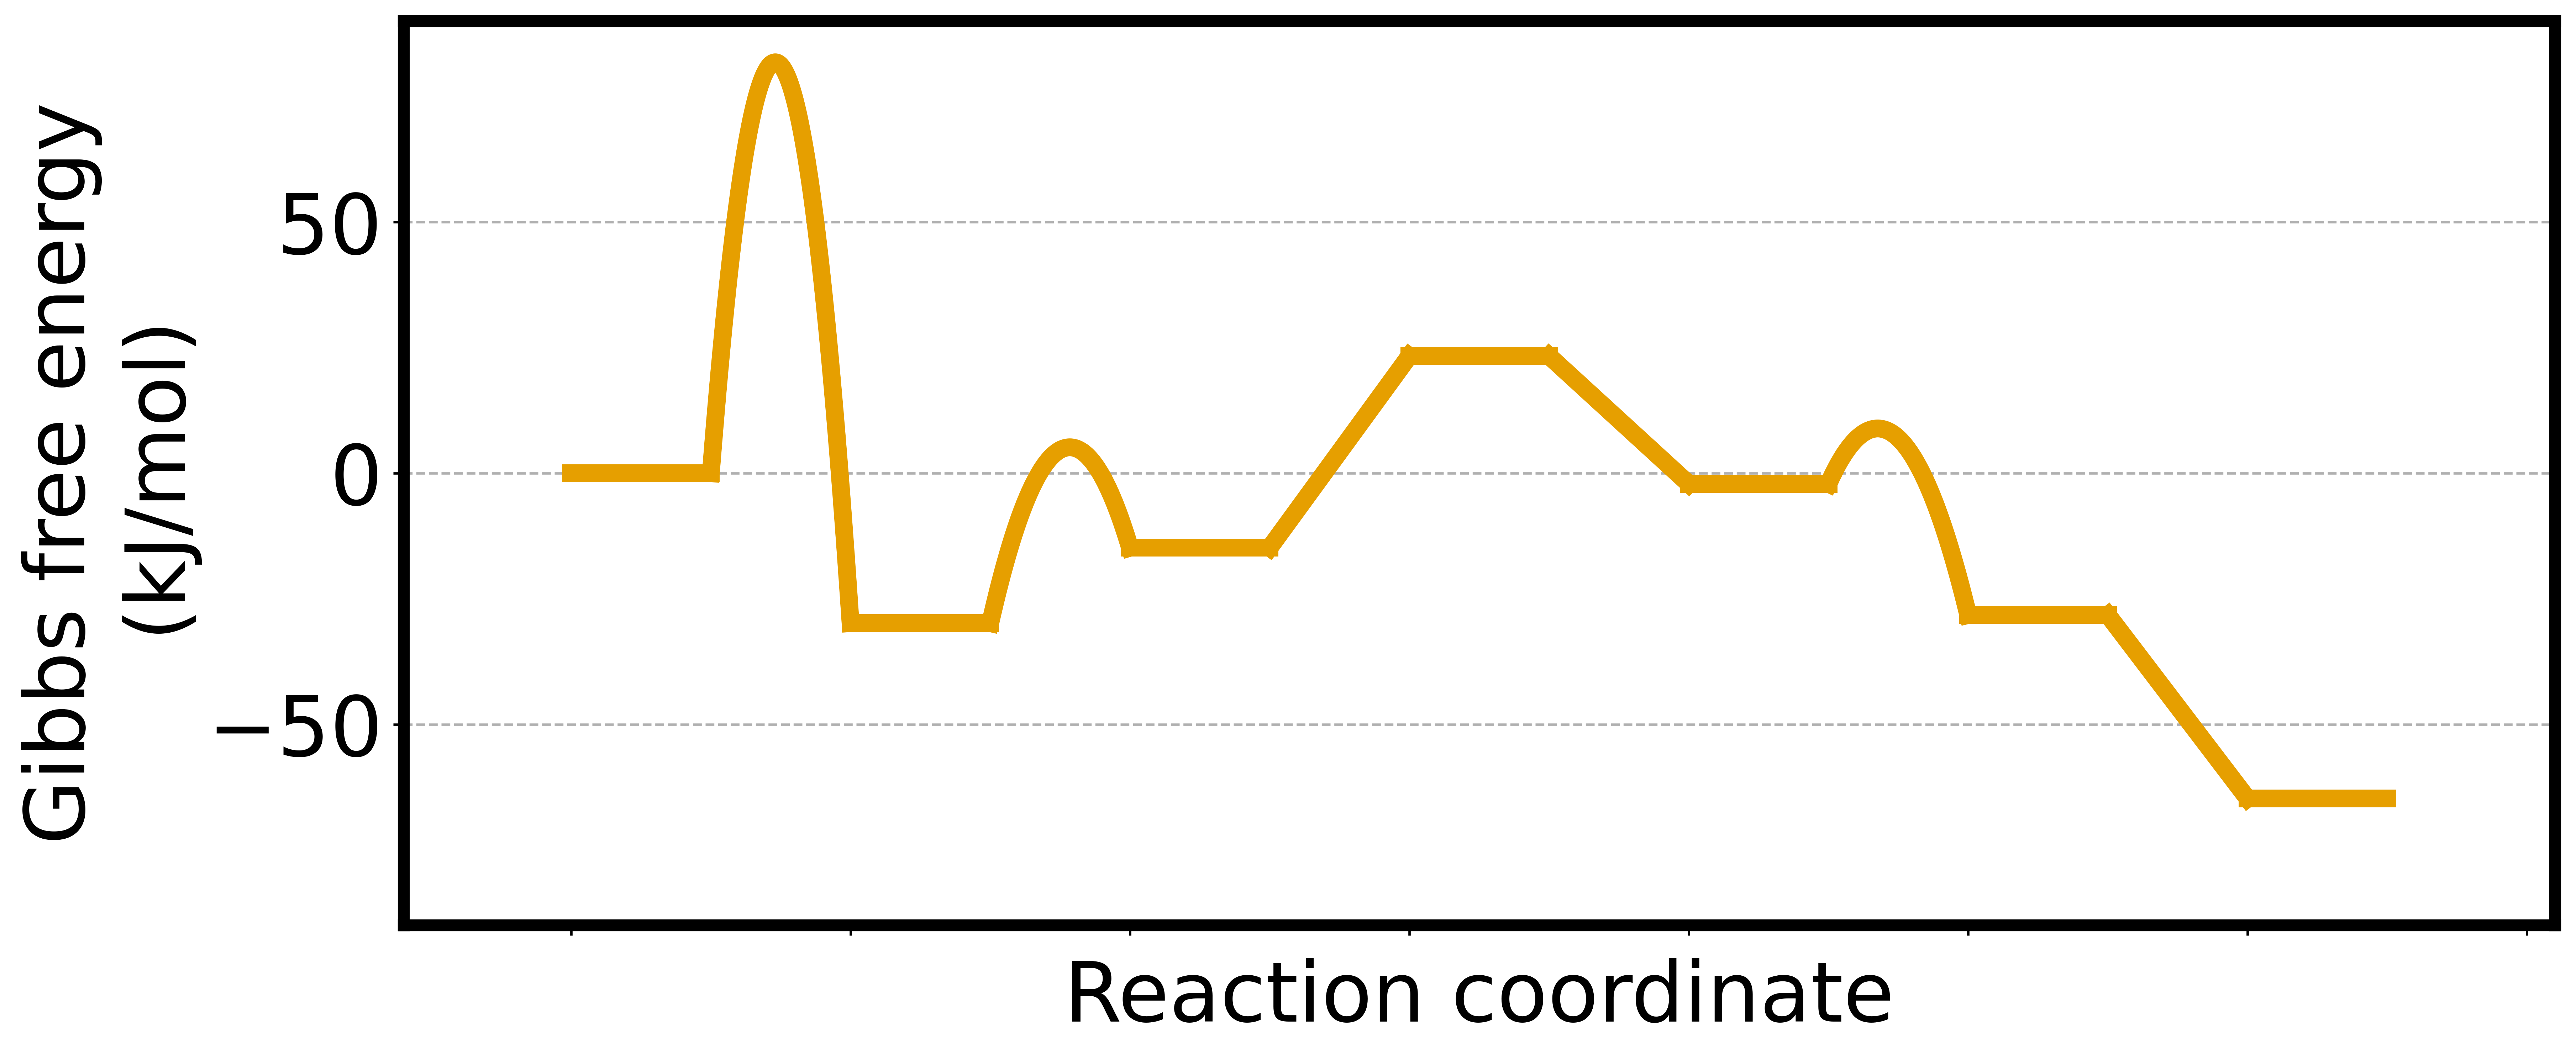

<Figure size 7800x3300 with 0 Axes>

In [7]:
dft = formatted_df_tri.query('temperature == 300 & pressure >= 1e5 & pressure <= 2e5')\
    .reset_index(drop=True).copy()
data = dft.copy()
data['order'] = data['order'].astype(str)
data.loc[-1, :] = data.loc[data['order'] == '2', :].iloc[0]
data.loc[-1, 'order'] = '2_0'
dE = data.loc[data['order'] == '1', ['rel_G_eV']].values[0][0] - data.loc[data['order'] == '2', ['rel_G_eV']].values[0][0]
data.loc[data.order.isin({'2_0',}), ['rel_G_eV']] = data.loc[data.order.isin({'1p',}), ['rel_G_eV']].values[0] - dE
data.loc[:, ['rel_G_eV']] -= data.loc[data['order'] == '2', ['rel_G_eV']].values[0][0]

EP = EnergyProfile(
    data, 
    energy_type=energy_type, 
    energy_unit=energy_unit)

plot_sequence_1 =  '2-->3-->4-->5-->6-->1p-->2_0'   # Show the sequence of intermediate along which the profile is constructed

systems_ls = [plot_sequence_1.split(sep='-->')
              ]

position_map = OrderedDict()
for systems in systems_ls:
    for i, system in enumerate(systems):
        position = 2 * i
        if system not in position_map:
            position_map[system] = position
    
xmax = max(position_map.values()) + 1

EP.plot()
energy_values = []
for systems in systems_ls:
    tmp_values = EP.get_energy_range(systems)
    energy_values.extend(tmp_values)

ymin = min(energy_values)
ymax = max(energy_values)
yrange = ymax - ymin
padding = 0.10 * yrange
colors = ["#56B4E9", "#009E73", "#E69F00"][::-1]
labels = ['', 'trimerization', 'direct']

for i, systems in enumerate(systems_ls):
    for system in systems:
        position = position_map[system]

        if system == systems[0]:
            EP.add_level(system=system, 
                         position=position, 
                         label=labels[i], 
                         color=colors[i])
        else:
            EP.add_level(system=system, 
                         position=position, 
                         color=colors[i])


    for system1, system2 in zip(systems[:-1], systems[1:]):
        EP.add_connection(system1=system1, 
                          system2=system2, 
                          color=colors[i])


for i, systems in enumerate(systems_ls):
    for j, system in enumerate(systems):
        position = position_map[system]
        # EP.add_structure_name(system=system,
        #                         position=position, 
        #                         fontsize=18)

plt.ylabel('Gibbs free energy\n(kJ/mol)', fontsize=28)
plt.xlabel('Reaction coordinate', fontsize=28)
plt.ylim(-90, 90)
plt.xlim(-1.2, 14.2)
EP.show(legend=False,
        outfile='profile.pdf')
plt.savefig('files/plots/profile.svg')

# Profile analysis

In [1]:
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorption
import numpy as np
import pandas as pd
import tqdm

temperatures = np.linspace(300, 600, 11)
pressures = np.linspace(1, 50, 11)

df = pd.DataFrame()

with tqdm.tqdm(total=len(temperatures) * len(pressures), desc='Processing') as pbar:
    for temperature in temperatures:
        for pressure in pressures:
            energy_barriers = EnergyBarriersSimplifyed(
                temperature=temperature,
                pressure=pressure
            )
            dft = pd.DataFrame(energy_barriers.energy_barriers | energy_barriers.way, index=[0])
            dft['temperature'] = temperature
            dft['pressure'] = pressure
            df = pd.concat([df, dft], ignore_index=True)
            pbar.update(1)
    
df = df.reset_index(drop=True)

Processing: 100%|██████████| 121/121 [00:20<00:00,  5.85it/s]


In [2]:
columns = ['insertion_tetra', 'deinsertion_tetra',	'elimination_tetra',	'deelimination_tetra']
df[columns].mean(), df[columns].std()

(insertion_tetra         82.083708
 deinsertion_tetra      119.344125
 elimination_tetra       52.863669
 deelimination_tetra     58.453506
 dtype: float64,
 insertion_tetra         1.324582
 deinsertion_tetra      13.895972
 elimination_tetra      20.309989
 deelimination_tetra    14.697828
 dtype: float64)

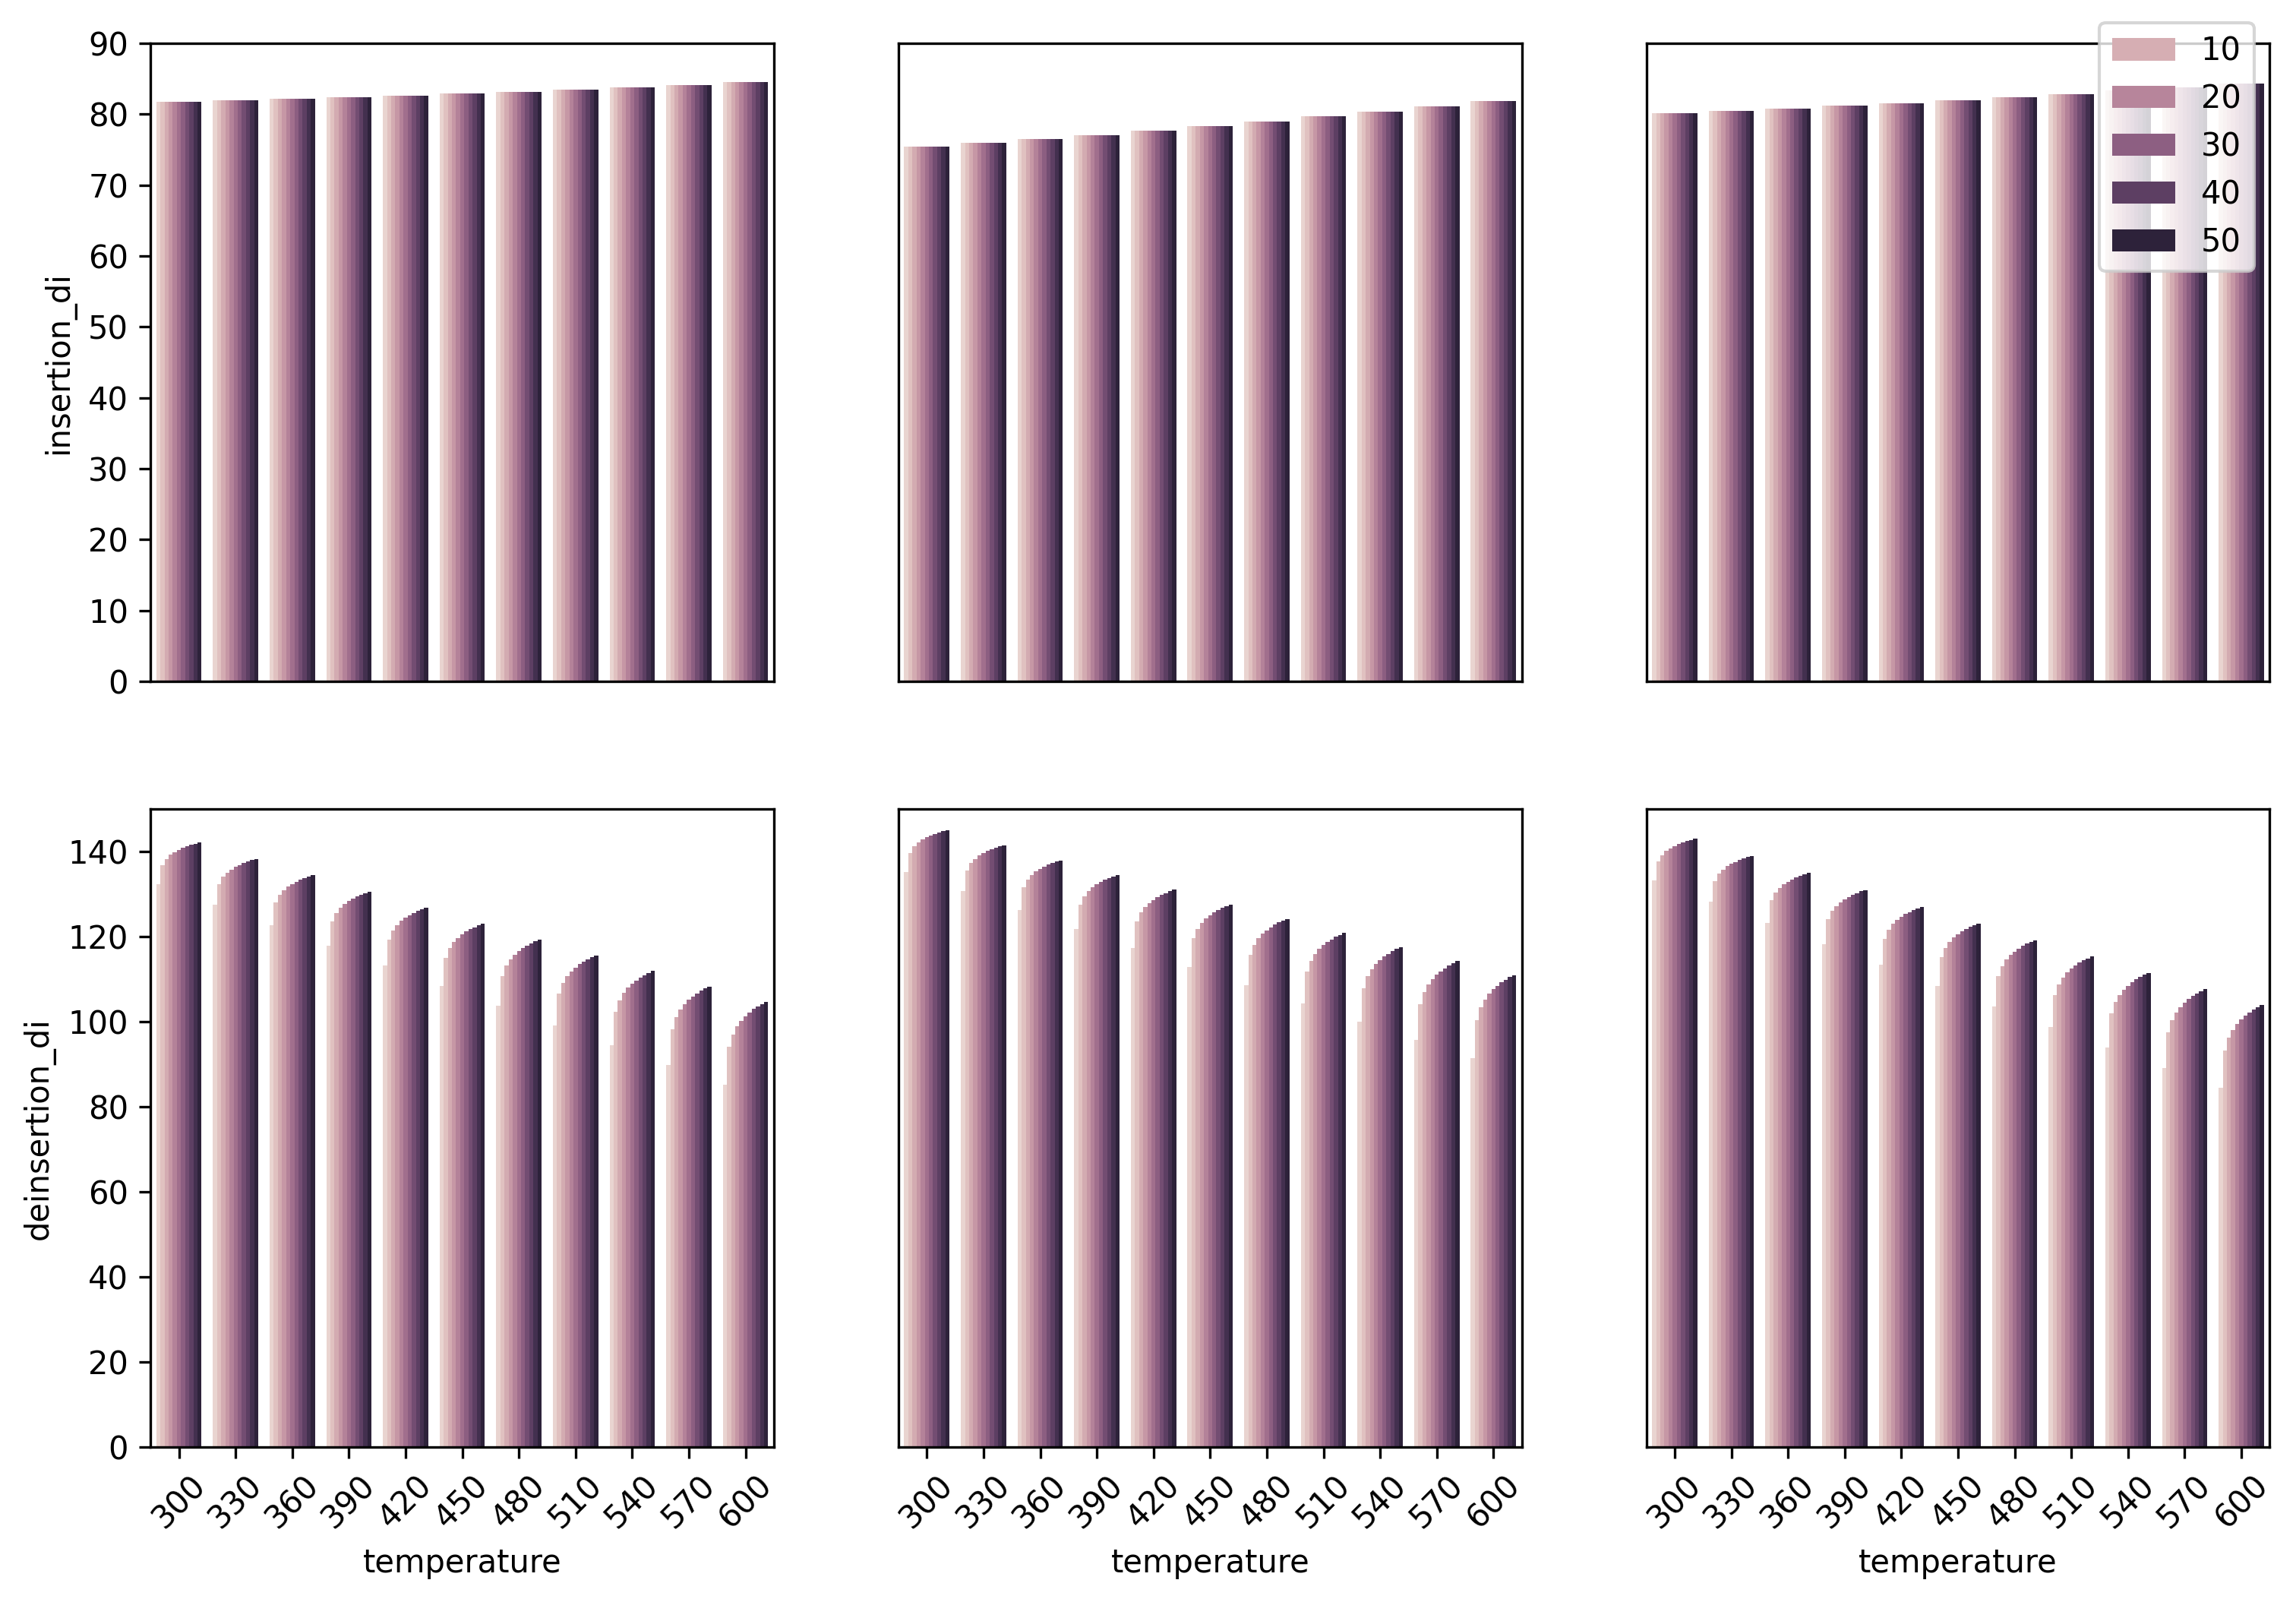

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(12, 8), dpi=300)


for cnt, i in enumerate(('di', 'tri', 'tetra')):
    sns.barplot(data=df, y=f'insertion_{i}', x='temperature', hue='pressure', ax=axs[0, cnt])
    sns.barplot(data=df, y=f'deinsertion_{i}', x='temperature', hue='pressure', ax=axs[1, cnt])
    axs[0, cnt].set_ylim(0, 90)
    axs[1, cnt].set_ylim(0, 150)
    axs[0, cnt].set_xlabel('')
    axs[0, cnt].set_xticks([])
    axs[1, cnt].set_xticks(np.arange(temperatures.shape[0]))
    axs[1, cnt].set_xticklabels([int(i) for i in temperatures], rotation=45)
    handles, labels = axs[1, cnt].get_legend_handles_labels()
    axs[1, cnt].legend_.remove()
    axs[0, cnt].legend_.remove()
    
    if cnt > 0:
        axs[0, cnt].set_ylabel('')
        axs[1, cnt].set_ylabel('')
        axs[0, cnt].set_yticks([])
        axs[1, cnt].set_yticks([])
        


fig.legend(handles, labels, bbox_to_anchor=[0.9, 0.9])

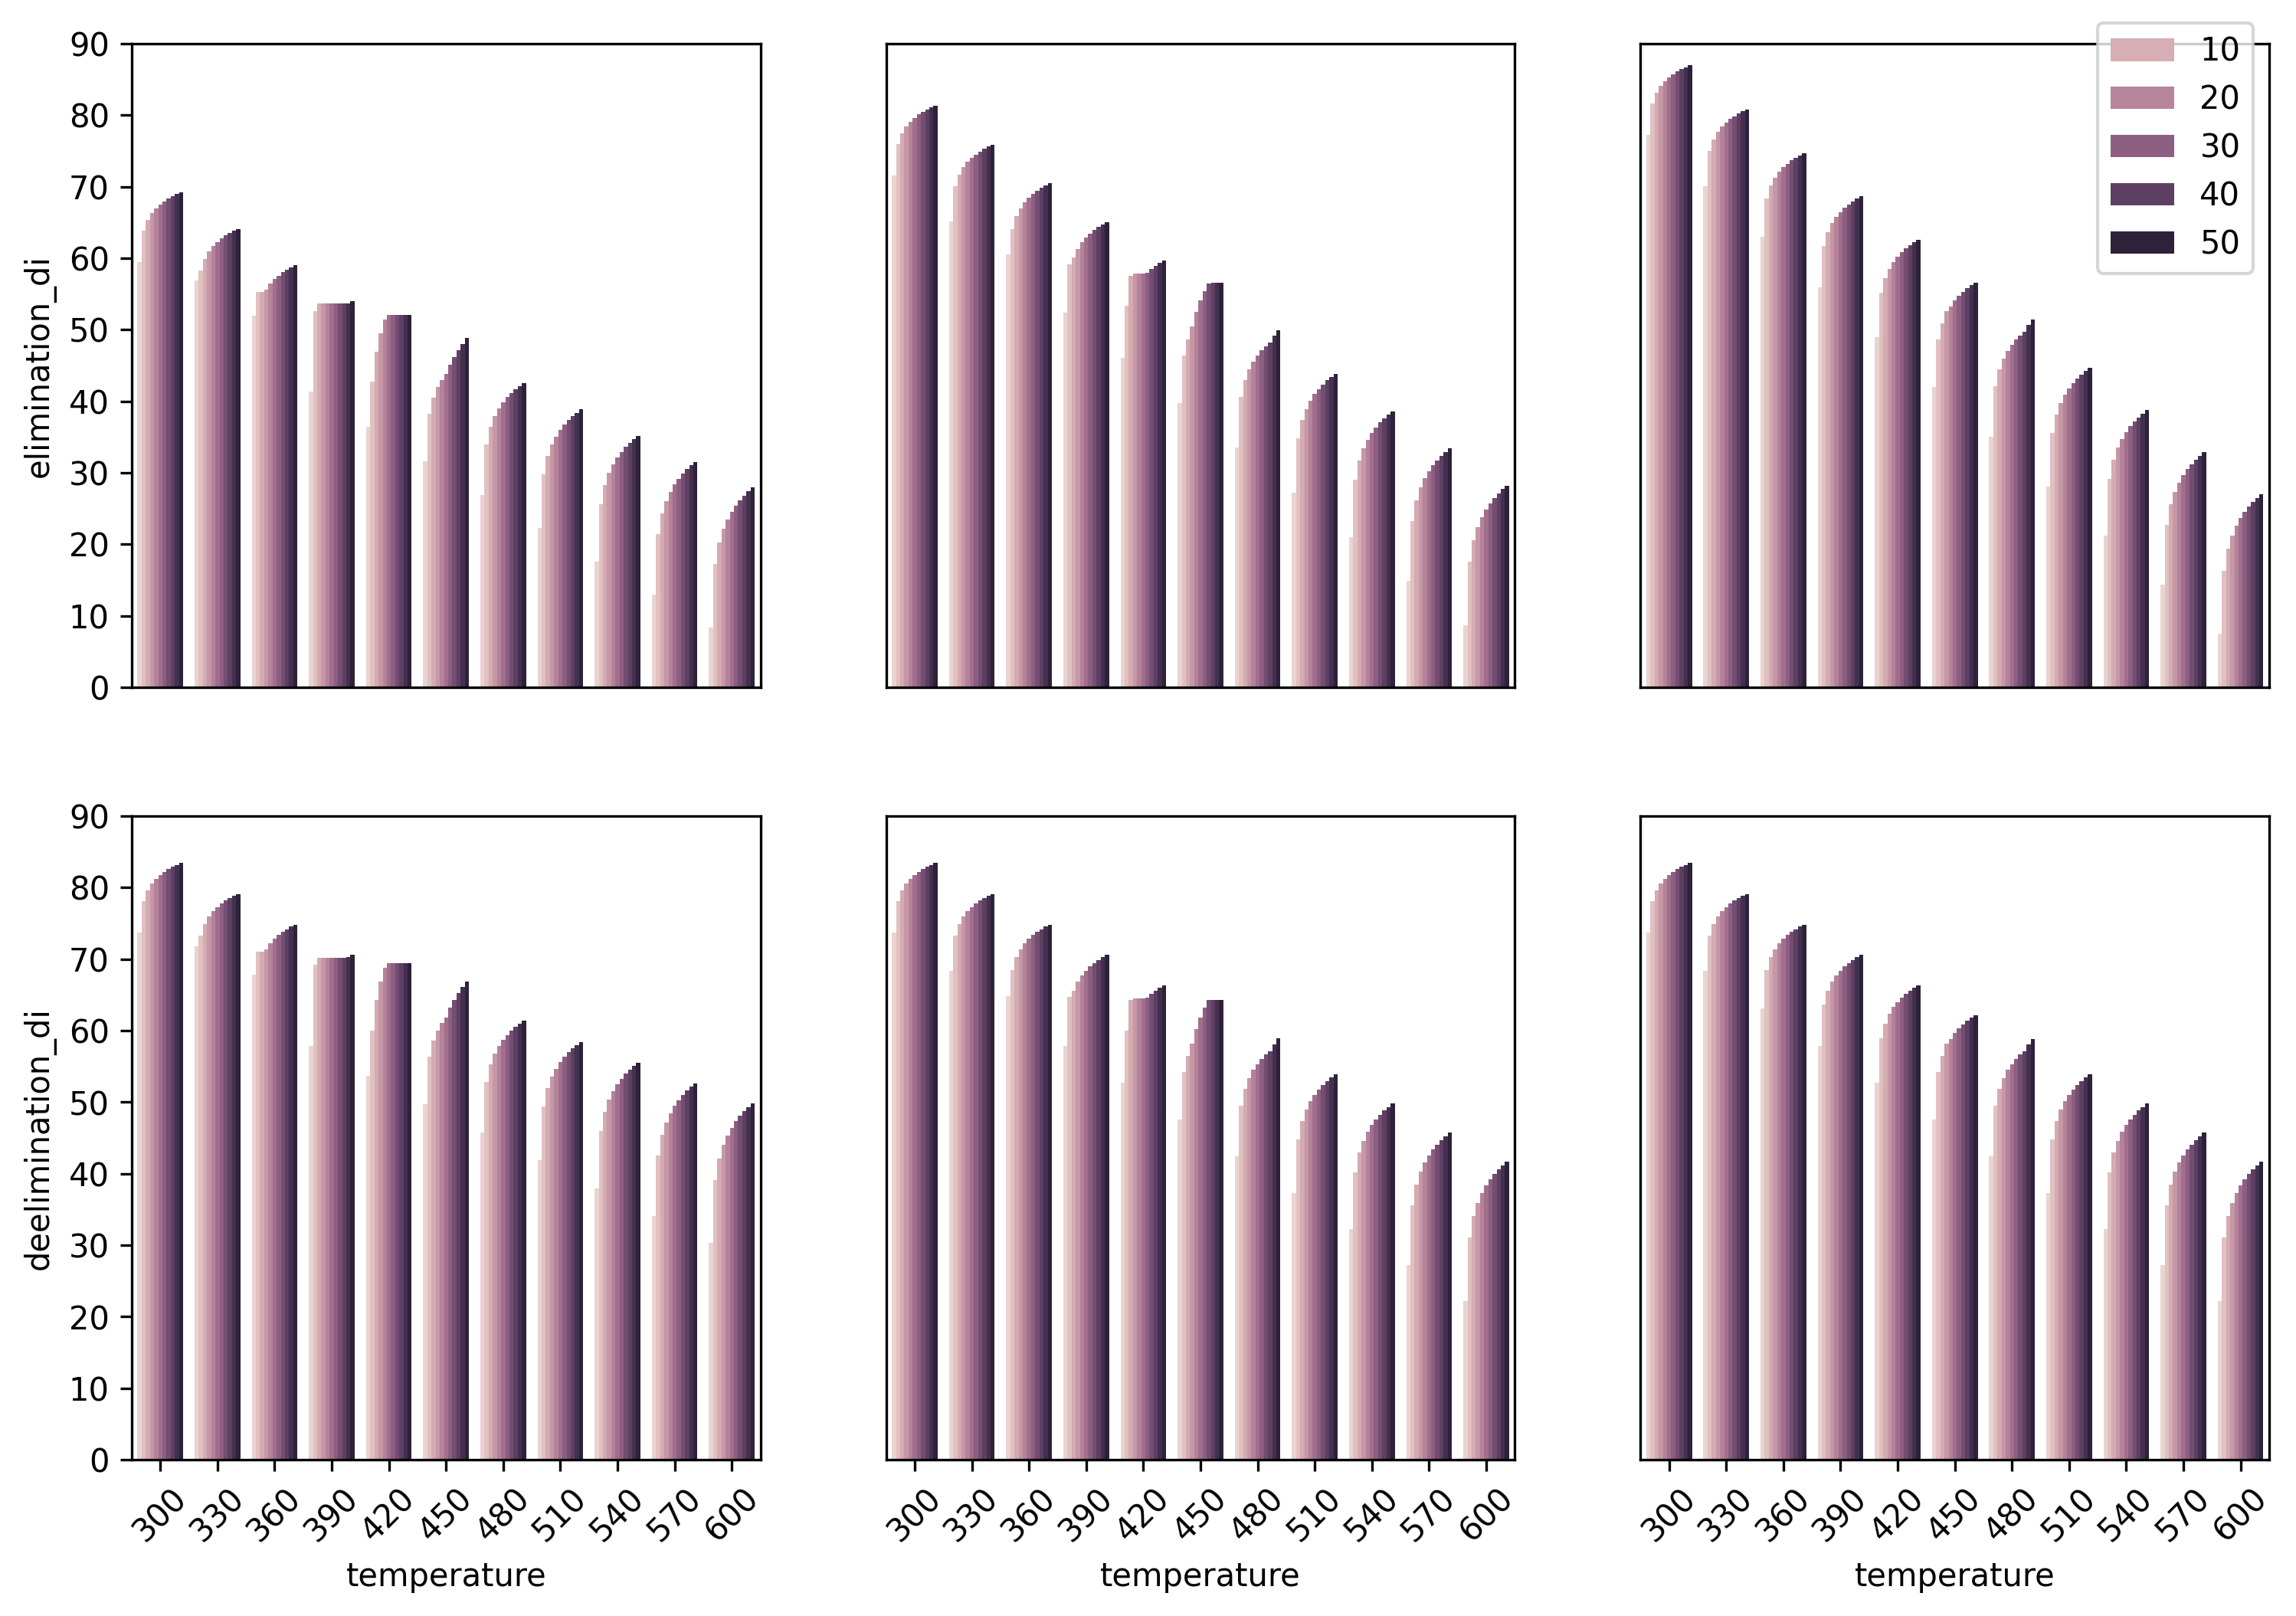

In [4]:
fig, axs = plt.subplots(2, 3, figsize=(12, 8), dpi=300)


for cnt, i in enumerate(('di', 'tri', 'tetra')):
    sns.barplot(data=df, y=f'elimination_{i}', x='temperature', hue='pressure', ax=axs[0, cnt])
    sns.barplot(data=df, y=f'deelimination_{i}', x='temperature', hue='pressure', ax=axs[1, cnt])
    axs[0, cnt].set_ylim(0, 90)
    axs[1, cnt].set_ylim(0, 90)
    axs[0, cnt].set_xlabel('')
    axs[0, cnt].set_xticks([])
    axs[1, cnt].set_xticks(np.arange(temperatures.shape[0]))
    axs[1, cnt].set_xticklabels([int(i) for i in temperatures], rotation=45)
    handles, labels = axs[1, cnt].get_legend_handles_labels()
    axs[1, cnt].legend_.remove()
    axs[0, cnt].legend_.remove()
    
    if cnt > 0:
        axs[0, cnt].set_ylabel('')
        axs[1, cnt].set_ylabel('')
        axs[0, cnt].set_yticks([])
        axs[1, cnt].set_yticks([])
        

fig.legend(handles, labels, bbox_to_anchor=[0.9, 0.9])

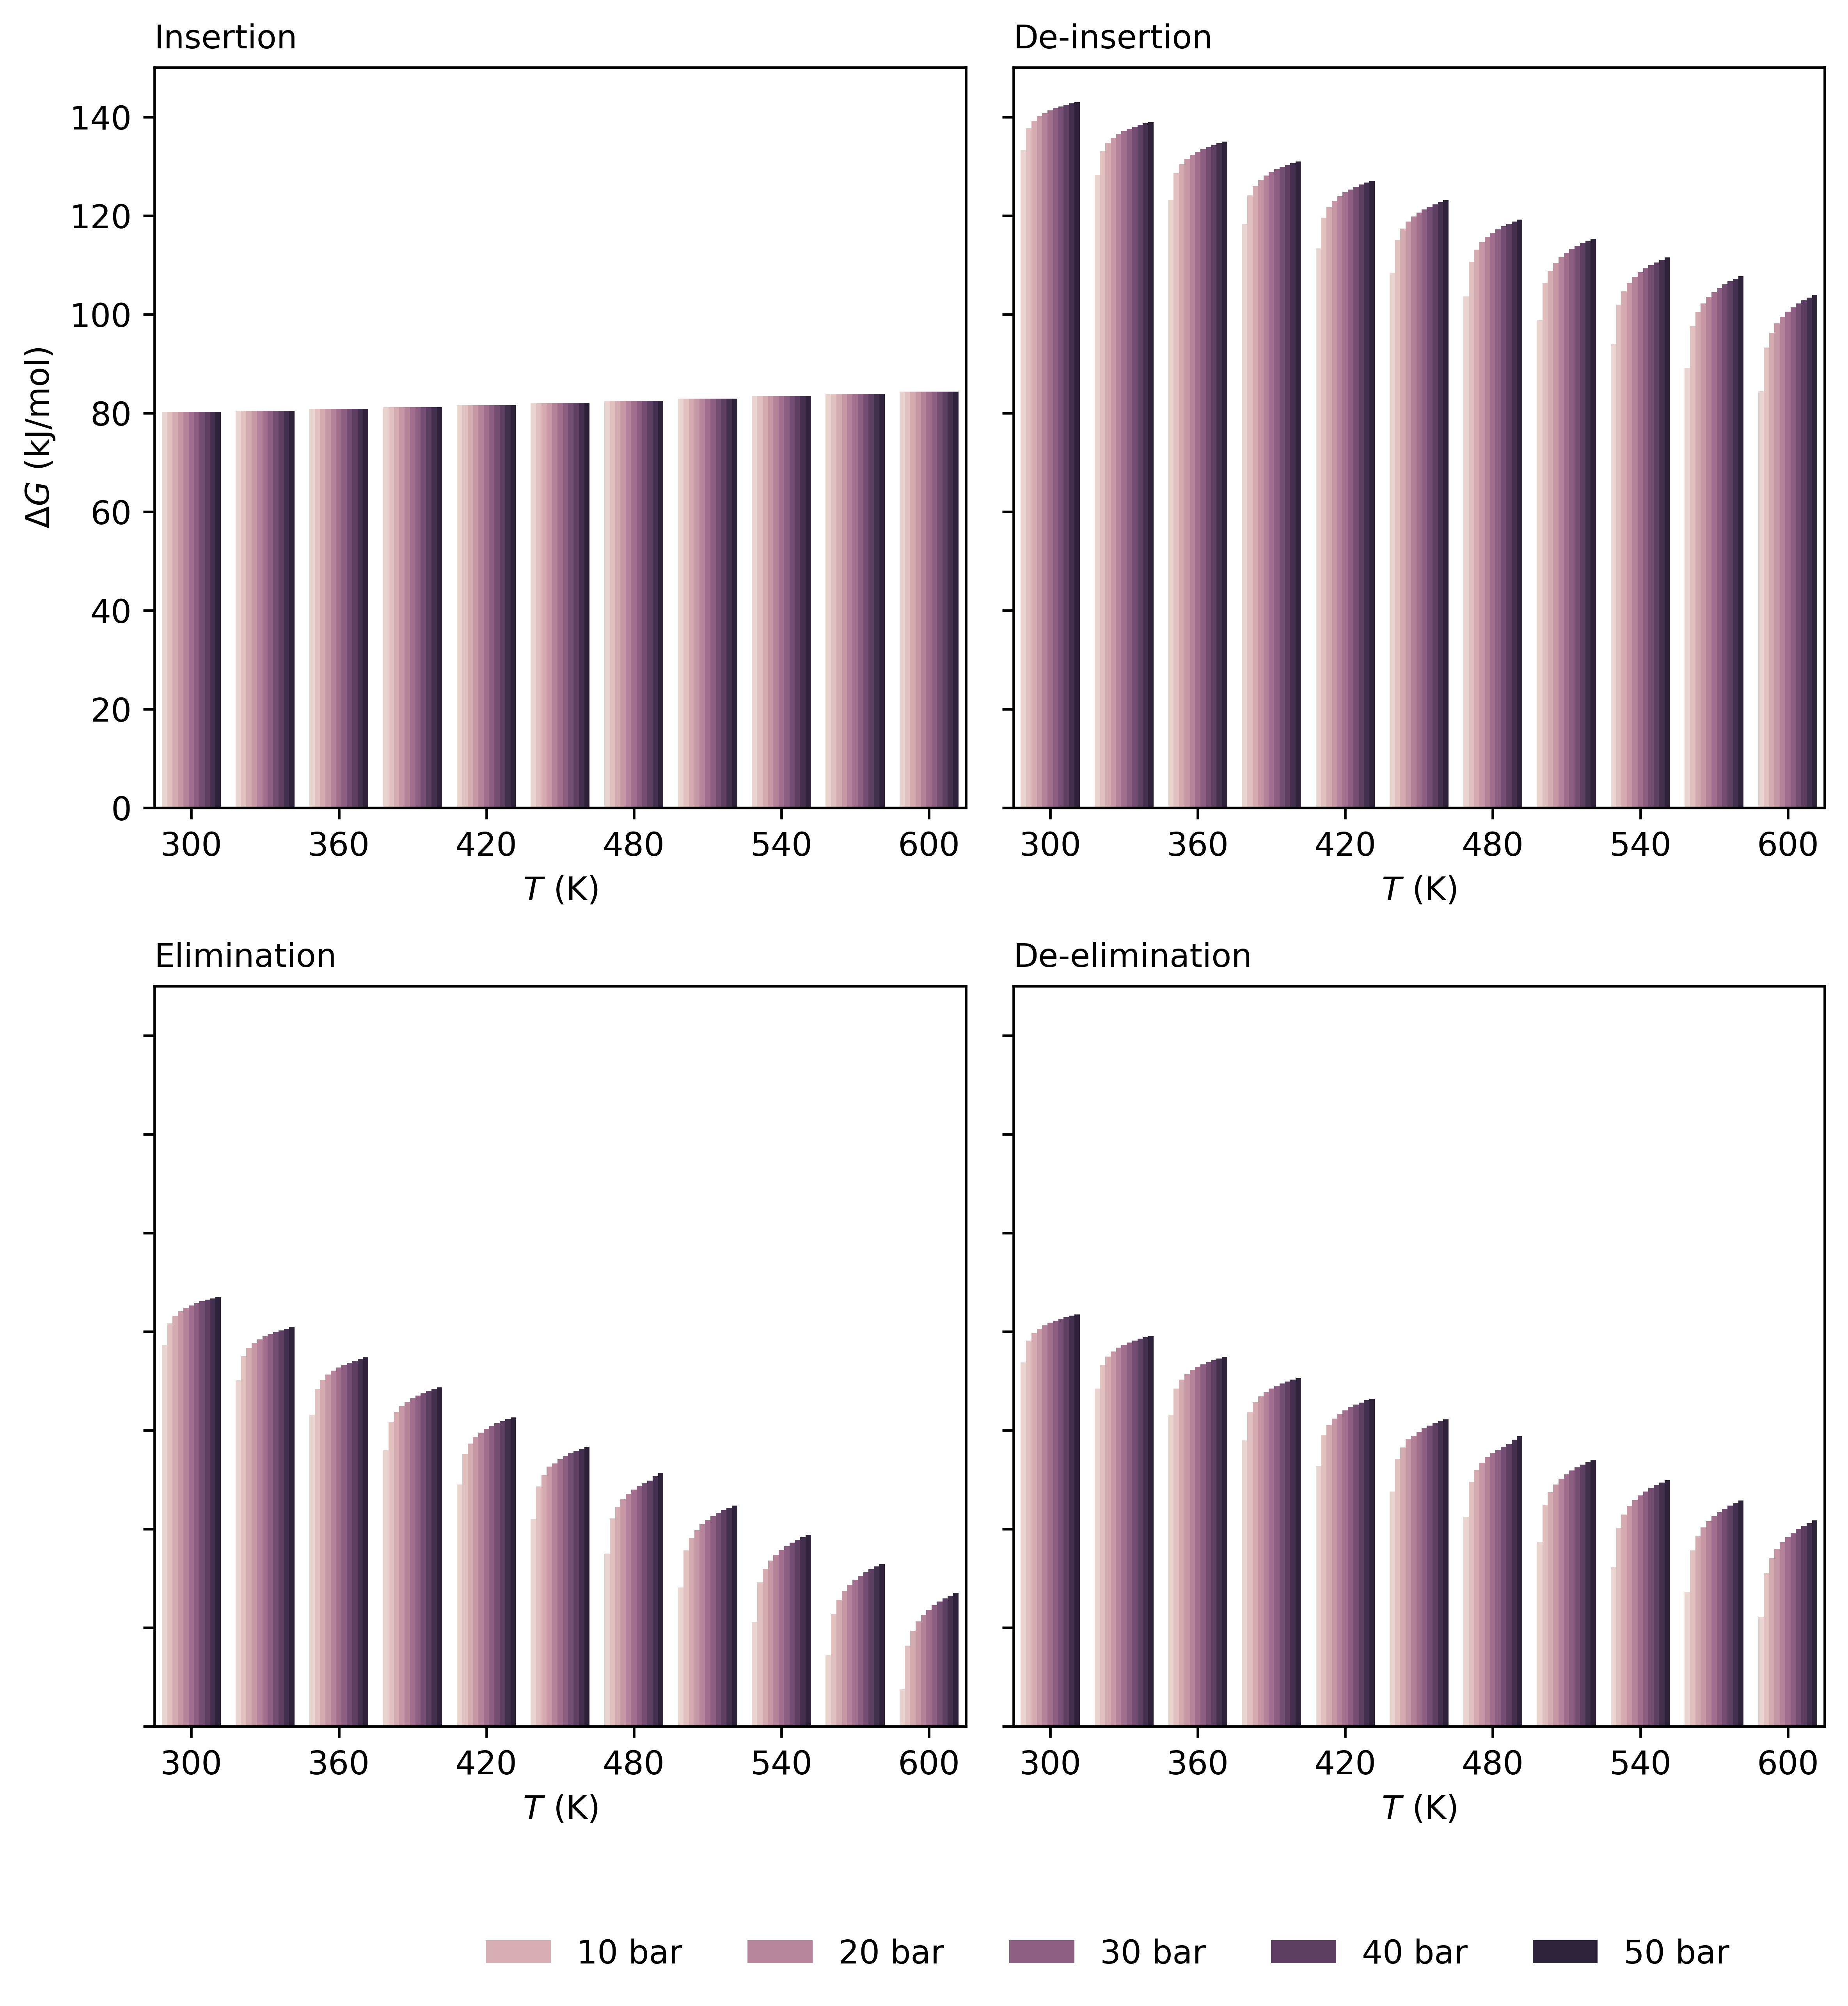

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(2, 2, figsize=(8, 8), dpi=600)

i = "tetra"

panels = [
    (f"insertion_{i}",    "Insertion"),
    (f"deinsertion_{i}",  "De-insertion"),
    (f"elimination_{i}",  "Elimination"),
    (f"deelimination_{i}","De-elimination"),
]

for ax, (ycol, title) in zip(axs.flatten(), panels):
    sns.barplot(
        data=df, x="temperature", y=ycol, hue="pressure",
       
        ax=ax
    )
    ax.set_title(title, loc="left", fontsize=10)

# Axis styling
for cnt, ax in enumerate(axs.flatten()):
    ax.set_ylim(0, 150)
    # X-ticks only on bottom row
    ax.set_xlabel(r"$T\ \mathrm{(K)}$")
    ax.set_xticks(np.arange(len(temperatures))[::2])
    ax.set_xticklabels([int(t) for t in temperatures[::2]], rotation=0)
    if cnt == 0:
        ax.set_ylabel(r"$\Delta G\ \mathrm{(kJ/mol)}$")
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])
    # Remove per-axes legends
    if ax.legend_:
        ax.legend_.remove()

# Global legend
handles, labels = axs[0, 0].get_legend_handles_labels()
labels = [f"{lab} bar" for lab in labels]
fig.legend(
    handles, labels, loc="center left",
    bbox_to_anchor=(0.25, -0.05), frameon=False, ncol=5
)

fig.tight_layout()
fig.savefig("files/plots/energy_barriers.pdf", bbox_inches="tight")
fig.savefig("files/plots/energy_barriers.svg", bbox_inches="tight")


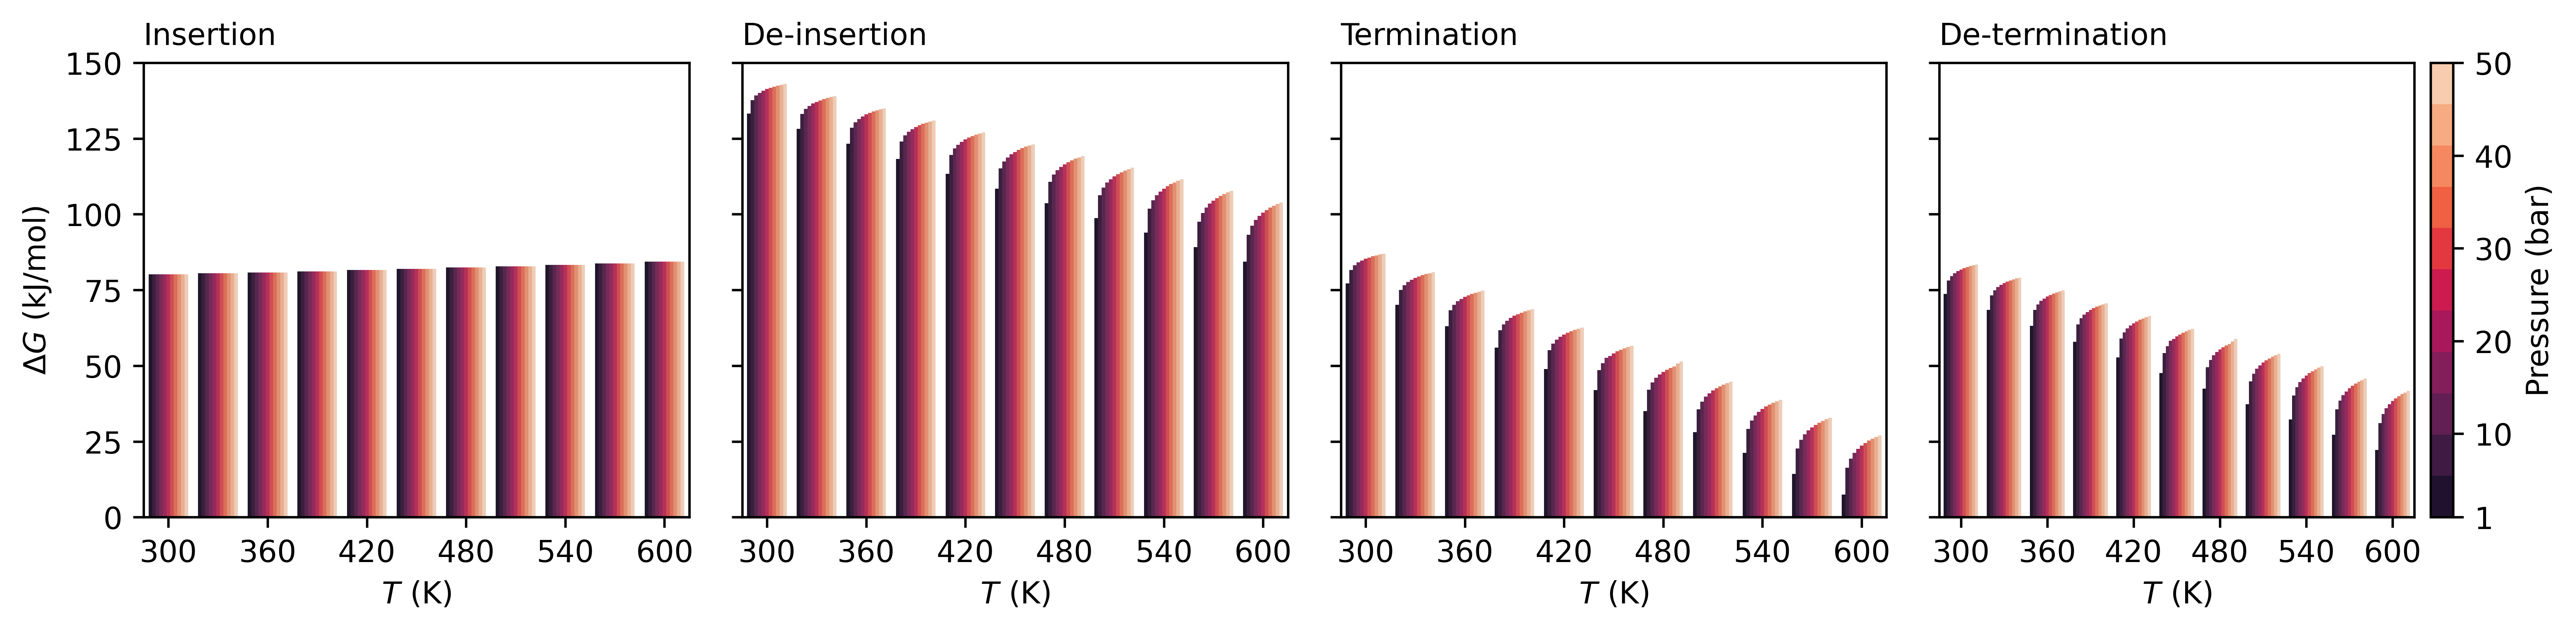

In [38]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import matplotlib as mpl

fig, axs = plt.subplots(1, 4, figsize=(12, 3), dpi=600)

i = "tetra"

panels = [
    (f"insertion_{i}",    "Insertion"),
    (f"deinsertion_{i}",  "De-insertion"),
    (f"elimination_{i}",  "Termination"),
    (f"deelimination_{i}","De-termination"),
]

# Extract pressures from df
pressures = sorted(df["pressure"].unique())

# Build continuous colormap matching seaborn palette
palette = sns.color_palette("rocket", len(pressures))
cmap = mpl.colors.ListedColormap(palette)

norm = mpl.colors.Normalize(vmin=min(pressures), vmax=max(pressures))
sm = mpl.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

# Plotting
for ax, (ycol, title) in zip(axs.flatten(), panels):
    sns.barplot(
        data=df,
        x="temperature",
        y=ycol,
        hue="pressure",
        palette=palette,
        ax=ax
    )
    ax.set_title(title, loc="left", fontsize=10)

# Axis styling
for cnt, ax in enumerate(axs.flatten()):
    ax.set_ylim(0, 150)

    ax.set_xlabel(r"$T\ \mathrm{(K)}$")
    ax.set_xticks(np.arange(len(temperatures))[::2])
    ax.set_xticklabels([int(t) for t in temperatures[::2]], rotation=0)

    if cnt == 0:
        ax.set_ylabel(r"$\Delta G\ \mathrm{(kJ/mol)}$")
    else:
        ax.set_ylabel("")
        ax.set_yticklabels([])

    # Remove per-axis legends
    if ax.legend_:
        ax.legend_.remove()



# --- Add Continuous Colorbar ---
cbar = fig.colorbar(
    sm, ax=axs[3],
    orientation='vertical',
    fraction=0.1,
    pad=0.03
)
cbar.set_ticks([1, 10, 20, 30, 40, 50])
cbar.set_ticklabels(["1", "10", "20", "30", "40", "50"])

cbar.set_label("Pressure (bar)")

fig.tight_layout()
fig.savefig("files/plots/energy_barriers.pdf", bbox_inches="tight")
fig.savefig("files/plots/energy_barriers.svg", bbox_inches="tight")


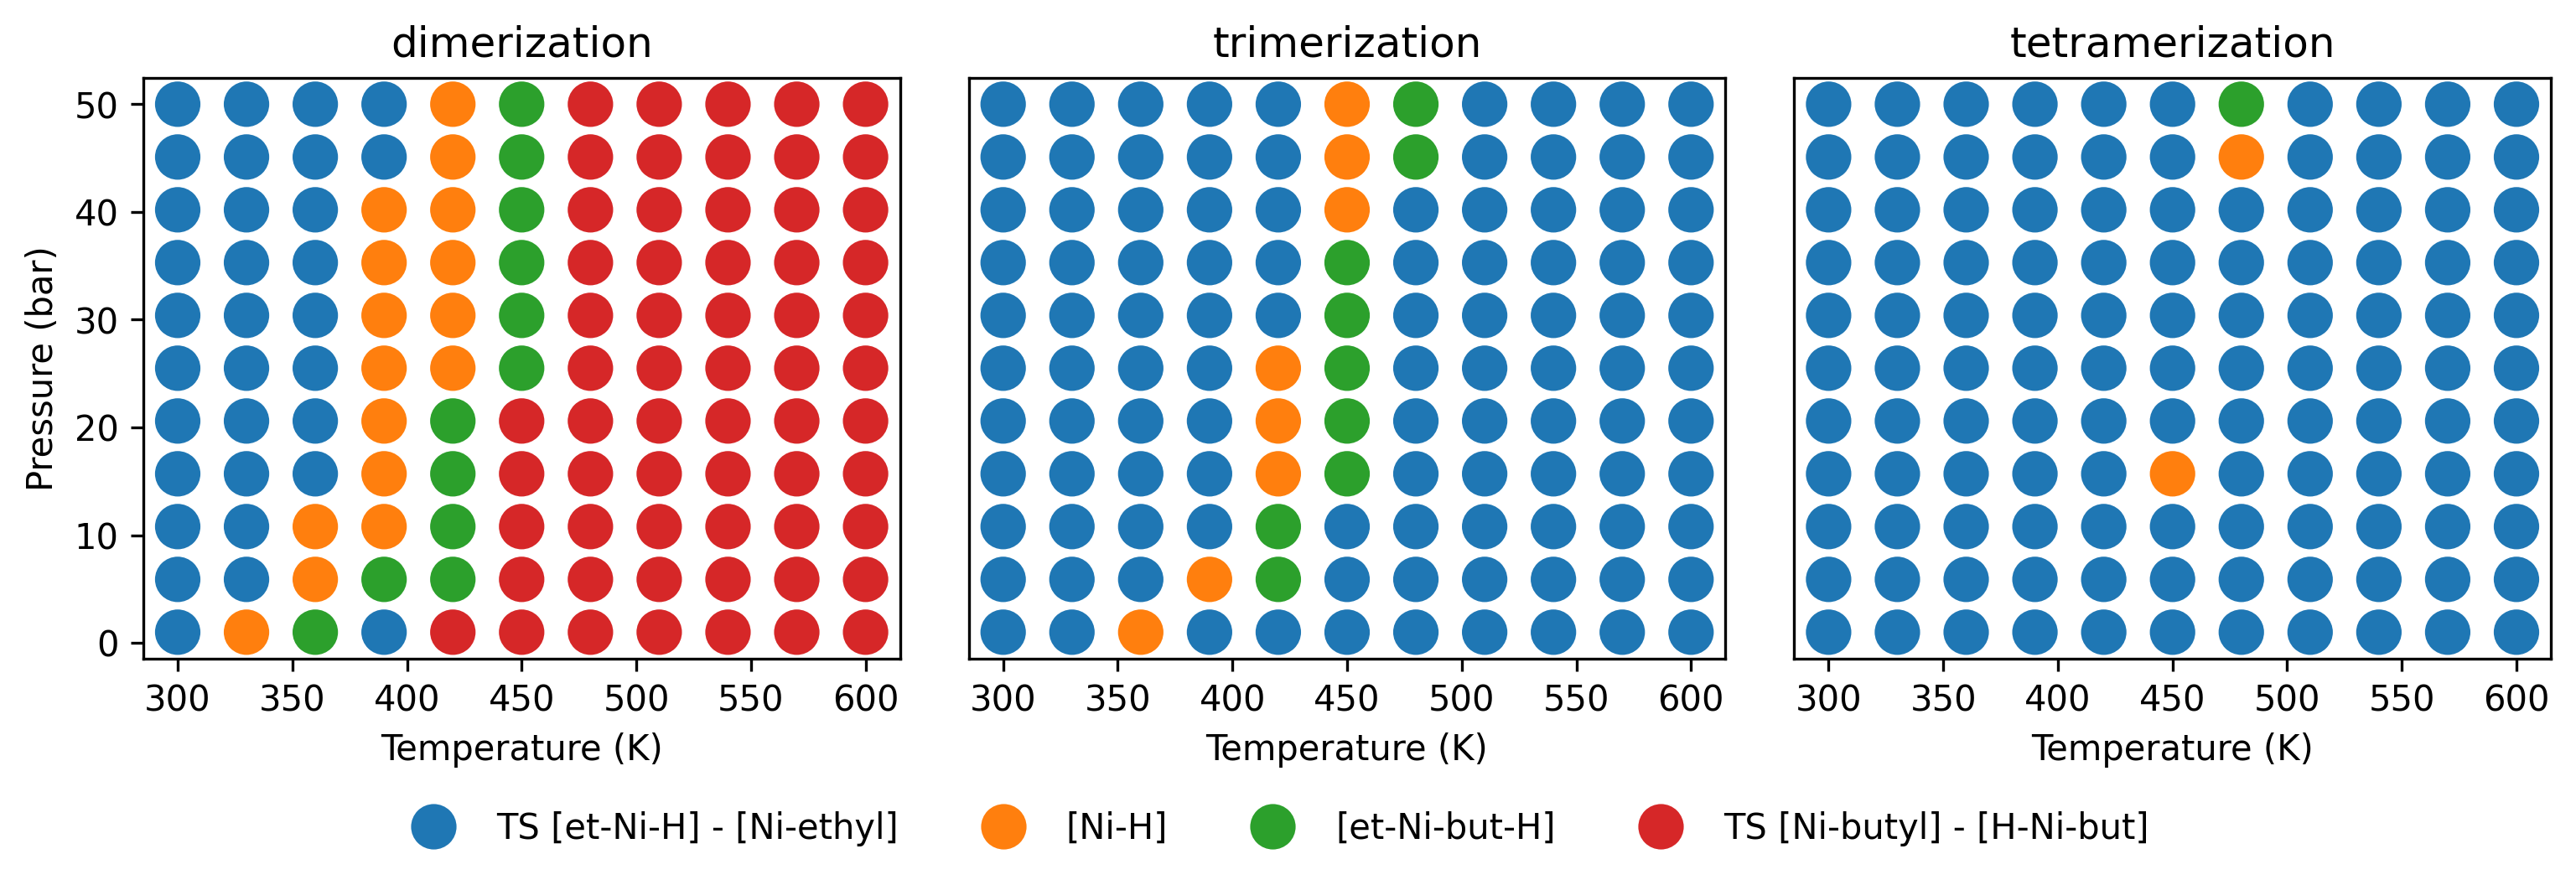

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(12,3), dpi=300)

for cnt, i in enumerate(('di', 'tri', 'tetra')):
    sns.scatterplot(
        data=df,
        x="temperature",
        y="pressure",
        hue=i,          # color by 'di'
        palette="tab10",   # pick any palette (tab10, Set2, etc.)
        s=200,              # marker size
        ax=axs[cnt]
    )
    axs[cnt].set_title(f"{i}merization")
    axs[cnt].set_xlabel("Temperature (K)")
    axs[cnt].set_ylabel("Pressure (bar)")
    if cnt > 0:
        axs[cnt].set_ylabel('')
        axs[cnt].set_yticks([])
    box = axs[cnt].get_position()
    axs[cnt].set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = axs[0].get_legend_handles_labels()    
    axs[cnt].legend_.remove()


labels = ['TS [et-Ni-H] - [Ni-ethyl]', '[Ni-H]', '[et-Ni-but-H]', 'TS [Ni-butyl] - [H-Ni-but]']

fig.legend(handles, labels, bbox_to_anchor=[0.8, -0.05], ncol=5, frameon=False)

fig.savefig("files/plots/deelimination_paths.pdf", bbox_inches="tight")
fig.savefig("files/plots/deelimination_paths.svg", bbox_inches="tight")

In [8]:
df.to_pickle('files/profile/energies.pkl')